# ECG Classification — 12SL Features with PCA

A separate experiment using PCA on the numerical features in `12sl_features.csv`.

Use the same ECGs, patient-wise splits, label order and preprocessing as the previous 53-label experiment. Keep the original model settings and reduce the input dimensions using PCA instead. The classical One-vs-Rest models are trained once for 53 labels; the MLP is trained separately for 53, 10 and 5 labels.

PCA models are saved under `12sl_feature_models/pca_results/variance_95`. The previously trained non-PCA models are not changed. Fold 10 remains reserved for final testing.

In [1]:
import numpy as np
import pandas as pd
import json
import joblib
import time
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score
)

from xgboost import XGBClassifier

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

/usr/lib/python3/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

In [2]:
FEATURE_PATH = Path("data/ptb-xl-plus/features/12sl_features.csv")
INDEX_DIR = Path("data/processed/12sl_median_images_final")

NUM_LABELS = 53
EXPERIMENT_ROOT = Path("data/processed/12sl_feature_models")
DATA_DIR = EXPERIMENT_ROOT / "top_53"
VARIANCE_TARGET = 0.95

RESULT_DIR = EXPERIMENT_ROOT / "pca_results" / f"variance_{VARIANCE_TARGET * 100:g}"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

features = pd.read_csv(FEATURE_PATH)
df = pd.read_csv(INDEX_DIR / "training_index_with_folds.csv")

print("Feature data:", features.shape)
print("ECG index:", df.shape)

Feature data: (21799, 783)
ECG index: (20914, 160)


In [3]:
assert features["ecg_id"].notna().all()
assert features["ecg_id"].is_unique

assert df["ecg_id"].is_unique
assert df[["ecg_id", "patient_id", "strat_fold"]].notna().all().all()
assert df["strat_fold"].isin(range(1, 11)).all()

missing_ids = df.loc[~df["ecg_id"].isin(features["ecg_id"]), "ecg_id"]

print("ECGs without features:", len(missing_ids))

assert missing_ids.empty, "Some ECGs are missing from the feature CSV. Check the dataset before comparing models."

features = features.set_index("ecg_id")

assert not any(col.startswith("label_") for col in features.columns)

print("Number of feature columns:", features.shape[1])


ECGs without features: 0
Number of feature columns: 782


## Patient-wise splitting

In [4]:
train_df = df[df["strat_fold"].between(1, 8)].copy()
val_df = df[df["strat_fold"] == 9].copy()
test_df = df[df["strat_fold"] == 10].copy()

assert set(train_df.patient_id).isdisjoint(val_df.patient_id)
assert set(train_df.patient_id).isdisjoint(test_df.patient_id)
assert set(val_df.patient_id).isdisjoint(test_df.patient_id)

assert (len(train_df), len(val_df), len(test_df)) == (16608, 2148, 2158)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


Training: 16608
Validation: 2148
Testing: 2158


In [5]:
with open(DATA_DIR / "selected_labels.json") as f:
    selected_labels = json.load(f)

label_cols = [
    col for col in df.columns
    if col.startswith("label_")
]

label_counts = train_df[label_cols].sum().sort_values(ascending=False, kind="stable")

labels_5 = label_counts.head(5).index.tolist()
labels_10 = label_counts.head(10).index.tolist()

assert len(selected_labels) == NUM_LABELS
assert set(labels_10).issubset(selected_labels)

print("Selected labels:", selected_labels)

distribution = pd.DataFrame({
    "Train": train_df[selected_labels].sum(),
    "Validation": val_df[selected_labels].sum()
})

assert distribution["Train"].between(1, len(train_df)-1).all()
assert distribution["Validation"].between(1, len(val_df)-1).all()

display(distribution)


Selected labels: ['label_NSR', 'label_AB', 'label_NML', 'label_SBRAD', 'label_SRTH', 'label_ABR', 'label_IMI;AU', 'label_LAD3', 'label_BORDE', 'label_AFIB', 'label_FAV', 'label_LVH2', 'label_SAR', 'label_NST', 'label_PVC', 'label_ST&', 'label_NT', 'label_STACH', 'label_NSTT', 'label_2ST', 'label_LT', 'label_PAC', 'label_RBBB', 'label_SMI;AU', 'label_AMI;AU', 'label_LNGQT', 'label_LBBB', 'label_ASMI;AU', 'label_AFB', 'label_LAE', 'label_IRBBB', 'label_RVR', 'label_LOWV', 'label_IT', 'label_ABER', 'label_MSAR', 'label_QRSW-2ST', 'label_ALT', 'label_RAD', 'label_PSVC', 'label_LMI;AU', 'label_IVCB', 'label_STEMI', 'label_ILT', 'label_AT', 'label_ALMI;AU', 'label_UR', 'label_VPR', 'label_FLUT', 'label_IVCD', 'label_$SABCOND', 'label_BIFB', 'label_QRSW']


,Train,Validation
label_NSR,9641,1253
label_AB,8770,1069
label_NML,4590,635
label_SBRAD,2594,317
label_SRTH,1939,255
label_ABR,1931,256
label_IMI;AU,1714,196
label_LAD3,1495,187
label_BORDE,1317,188
label_AFIB,1071,129


## Load the same preprocessing

In [6]:
with open(DATA_DIR / "feature_columns.json") as f:
    feature_cols = json.load(f)

X_train_df = features.loc[train_df["ecg_id"], feature_cols].copy()
X_val_df = features.loc[val_df["ecg_id"], feature_cols].copy()

X_train_df = X_train_df.apply(pd.to_numeric, errors="raise")
X_val_df = X_val_df.apply(pd.to_numeric, errors="raise")

X_train_df = X_train_df.replace([np.inf, -np.inf], np.nan)
X_val_df = X_val_df.replace([np.inf, -np.inf], np.nan)

print("Training features:", X_train_df.shape)
print("Validation features:", X_val_df.shape)


Training features: (16608, 782)
Validation features: (2148, 782)


In [7]:
imputer = joblib.load(DATA_DIR / "imputer.pkl")
scaler = joblib.load(DATA_DIR / "scaler.pkl")

X_train = imputer.transform(X_train_df).astype(np.float32)
X_val = imputer.transform(X_val_df).astype(np.float32)

X_train_scaled = scaler.transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)


Training features: (16608, 782)
Validation features: (2148, 782)


In [8]:
assert train_df[selected_labels].isin([0, 1]).all().all()
assert val_df[selected_labels].isin([0, 1]).all().all()

y_train = train_df[selected_labels].to_numpy(dtype=np.uint8)
y_val = val_df[selected_labels].to_numpy(dtype=np.uint8)

train_ids = train_df["ecg_id"].to_numpy(dtype=np.int64)
val_ids = val_df["ecg_id"].to_numpy(dtype=np.int64)

assert np.array_equal(train_ids, np.load(DATA_DIR / "train_ids.npy"))
assert np.array_equal(val_ids, np.load(DATA_DIR / "validation_ecg_ids.npy"))
assert np.array_equal(y_train, np.load(DATA_DIR / "y_train.npy"))
assert np.array_equal(y_val, np.load(DATA_DIR / "y_val.npy"))

assert np.array_equal(X_train_df.index, train_ids)
assert np.array_equal(X_val_df.index, val_ids)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)


X_train: (16608, 782) y_train: (16608, 53)
X_val: (2148, 782) y_val: (2148, 53)


## PCA — selecting the number of components

The 12SL measurements have different units and some features contain overlapping information. After median imputation and standardization, PCA combines correlated features into principal components ordered by their explained variance.

Fit PCA on training data only. We examine how many components retain 90%, 95% and 99% of the variance and use the smallest number retaining at least 95% for this experiment. This is a compromise between dimensionality reduction and information retained, not a guarantee of better classification. Smaller-variance components may still be useful for predicting rare labels.

All models in this PCA experiment use the same reduced features, including the tree models. For trees, PCA can help runtime but can also reduce predictive performance. Compare the validation results with those of the original features.

In [9]:
# Save the preprocessing used by the PCA models
with open(RESULT_DIR / "feature_columns.json", "w") as f:

    json.dump(feature_cols, f, indent=4)

with open(RESULT_DIR / "selected_labels.json", "w") as f:

    json.dump(selected_labels, f, indent=4)

joblib.dump(imputer, RESULT_DIR / "imputer.pkl")
joblib.dump(scaler, RESULT_DIR / "scaler.pkl")

np.save(RESULT_DIR / "train_ids.npy", train_ids)
np.save(RESULT_DIR / "validation_ecg_ids.npy", val_ids)

np.save(RESULT_DIR / "y_train.npy", y_train)
np.save(RESULT_DIR / "y_val.npy", y_val)

In [10]:
# Fit PCA once to see the variance of all components
pca_path = RESULT_DIR / "pca.pkl"

if pca_path.exists():

    pca = joblib.load(pca_path)

    print("Saved PCA loaded.")

else:

    pca = PCA(svd_solver="full")

    start = time.perf_counter()

    pca.fit(X_train_scaled)

    print(f"PCA fitting time: {(time.perf_counter() - start):.2f} seconds")

    joblib.dump(pca, pca_path)

assert pca.n_features_in_ == X_train_scaled.shape[1]

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

assert np.isfinite(cumulative_variance).all()

Saved PCA loaded.


In [11]:
variance_levels = [0.90, 0.95, 0.99]

variance_results = []

for level in variance_levels:

    n = int(np.searchsorted(cumulative_variance, level) + 1)

    variance_results.append({
        "Target variance (%)": level * 100,
        "Number of components": n,
        "Retained variance (%)": cumulative_variance[n - 1] * 100,
        "Feature reduction (%)": (1 - n / X_train_scaled.shape[1]) * 100
    })

variance_results = pd.DataFrame(variance_results)

display(variance_results.round(4))

variance_results.to_csv(RESULT_DIR / "variance_comparison.csv", index=False)

,Target variance (%),Number of components,Retained variance (%),Feature reduction (%)
0,90.0,134,90.071503,82.8645
1,95.0,197,95.016800,74.8082
2,99.0,347,99.006798,55.6266


In [12]:
n_components = int(np.searchsorted(
    cumulative_variance, VARIANCE_TARGET
) + 1)

retained_variance = cumulative_variance[n_components - 1] * 100

print("Original features:", X_train_scaled.shape[1])
print("Selected PCA components:", n_components)
print(f"Variance retained: {retained_variance:.4f}%")
print(f"Variance discarded: {100 - retained_variance:.4f}%")

reduction = (1 - n_components / X_train_scaled.shape[1]) * 100

print(f"Feature reduction: {reduction:.2f}%")

pca_info = {
    "original_features": X_train_scaled.shape[1],
    "n_components": n_components,
    "variance_target": VARIANCE_TARGET,
    "retained_variance_percent": float(retained_variance)
}

with open(RESULT_DIR / "pca_info.json", "w") as f:

    json.dump(pca_info, f, indent=4)

Original features: 782
Selected PCA components: 197
Variance retained: 95.0168%
Variance discarded: 4.9832%
Feature reduction: 74.81%


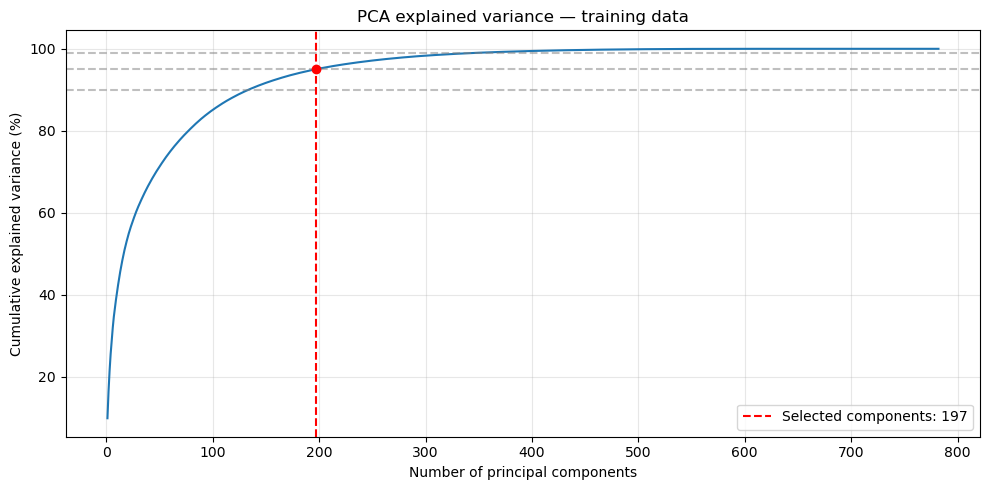

In [13]:
components = np.arange(1, len(cumulative_variance) + 1)

plt.figure(figsize=(10, 5))

plt.plot(components, cumulative_variance * 100)

for level in variance_levels:

    plt.axhline(level * 100, color="grey", linestyle="--", alpha=0.5)

plt.axvline(n_components, color="red", linestyle="--",
            label=f"Selected components: {n_components}")

plt.scatter(n_components, retained_variance, color="red", zorder=3)

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("PCA explained variance — training data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(RESULT_DIR / "pca_explained_variance.png", dpi=200)
plt.show()

variance_df = pd.DataFrame({
    "Component": components,
    "Explained variance (%)": explained_variance * 100,
    "Cumulative variance (%)": cumulative_variance * 100
})

variance_df.to_csv(RESULT_DIR / "pca_explained_variance.csv", index=False)

In [14]:
# Keep only the selected principal components
X_train_pca = pca.transform(X_train_scaled)[:, :n_components]
X_val_pca = pca.transform(X_val_scaled)[:, :n_components]

X_train_pca = np.ascontiguousarray(X_train_pca, dtype=np.float32)
X_val_pca = np.ascontiguousarray(X_val_pca, dtype=np.float32)

assert np.isfinite(X_train_pca).all()
assert np.isfinite(X_val_pca).all()

print("Training data before PCA:", X_train_scaled.shape)
print("Training data after PCA:", X_train_pca.shape)

print("Validation data before PCA:", X_val_scaled.shape)
print("Validation data after PCA:", X_val_pca.shape)

np.save(RESULT_DIR / "X_train_pca.npy", X_train_pca)
np.save(RESULT_DIR / "X_val_pca.npy", X_val_pca)

Training data before PCA: (16608, 782)
Training data after PCA: (16608, 197)
Validation data before PCA: (2148, 782)
Validation data after PCA: (2148, 197)


## Model evaluation

In [15]:
def calculate_metrics(targets, scores, threshold=0.5):
    assert targets.shape == scores.shape

    predictions = (scores >= threshold).astype(int)

    return {
        "Macro AUROC": roc_auc_score(
            targets, scores, average="macro"
        ),

        "Macro AUPRC": average_precision_score(
            targets, scores, average="macro"
        ),

        "Macro F1": f1_score(
            targets, predictions,
            average="macro", zero_division=0
        ),

        "Micro F1": f1_score(
            targets, predictions,
            average="micro", zero_division=0
        )
    }

def print_metrics(metrics):
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")


## Logistic Regression

In [16]:
lr_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ),
    n_jobs=2,
    verbose=10
)

In [17]:
lr_path = RESULT_DIR / "logistic_regression.pkl"

if lr_path.exists():

    lr_model = joblib.load(lr_path)

    print("Saved Logistic Regression PCA model loaded.")

else:

    start = time.perf_counter()

    lr_model.fit(X_train_pca, y_train)

    print("Logistic Regression training completed.")
    print(f"Training time: {(time.perf_counter() - start) / 60:.2f} minutes")

    joblib.dump(lr_model, lr_path)

assert len(lr_model.estimators_) == NUM_LABELS
assert lr_model.n_features_in_ == n_components

Saved Logistic Regression PCA model loaded.


In [18]:
lr_val_probs = lr_model.predict_proba(X_val_pca)

lr_metrics = calculate_metrics(y_val, lr_val_probs, threshold=0.5)

print_metrics(lr_metrics)

Macro AUROC: 0.8897
Macro AUPRC: 0.4610
Macro F1: 0.4198
Micro F1: 0.6755


## Random Forest

In [19]:
rf_model = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),
    n_jobs=1,
    verbose=10
)

In [20]:
rf_path = RESULT_DIR / "random_forest.pkl"

if rf_path.exists():

    rf_model = joblib.load(rf_path)

    print("Saved Random Forest PCA model loaded.")

else:

    start = time.perf_counter()

    rf_model.fit(X_train_pca, y_train)

    print("Random Forest training completed.")
    print(f"Training time: {(time.perf_counter() - start) / 60:.2f} minutes")

    joblib.dump(rf_model, rf_path)

assert len(rf_model.estimators_) == NUM_LABELS
assert rf_model.n_features_in_ == n_components

Saved Random Forest PCA model loaded.


In [21]:
rf_val_probs = rf_model.predict_proba(X_val_pca)

rf_metrics = calculate_metrics(y_val, rf_val_probs, threshold=0.5)

print_metrics(rf_metrics)

Macro AUROC: 0.8699
Macro AUPRC: 0.3402
Macro F1: 0.1134
Micro F1: 0.5197


## SVM

In [22]:
svm_model = OneVsRestClassifier(
    LinearSVC(
        C=1.0,
        dual=False,
        max_iter=2000,
        random_state=42
    ),
    n_jobs=2,
    verbose=10
)

In [23]:
svm_path = RESULT_DIR / "linear_svm.pkl"

if svm_path.exists():

    svm_model = joblib.load(svm_path)

    print("Saved SVM PCA model loaded.")

else:

    start = time.perf_counter()

    svm_model.fit(X_train_pca, y_train)

    print("SVM training completed.")
    print(f"Training time: {(time.perf_counter() - start) / 60:.2f} minutes")

    joblib.dump(svm_model, svm_path)

assert len(svm_model.estimators_) == NUM_LABELS
assert svm_model.n_features_in_ == n_components

Saved SVM PCA model loaded.


In [24]:
svm_val_scores = svm_model.decision_function(X_val_pca)

svm_metrics = calculate_metrics(y_val, svm_val_scores, threshold=0.0)

print_metrics(svm_metrics)

Macro AUROC: 0.8832
Macro AUPRC: 0.4551
Macro F1: 0.3928
Micro F1: 0.6643


## XGBoost

In [25]:
xgb_model = OneVsRestClassifier(
    XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        max_bin=128,
        random_state=42,
        n_jobs=2
    ),
    n_jobs=1,
    verbose=10
)

In [26]:
xgb_path = RESULT_DIR / "xgboost.pkl"

if xgb_path.exists():

    xgb_model = joblib.load(xgb_path)

    print("Saved XGBoost PCA model loaded.")

else:

    start = time.perf_counter()

    xgb_model.fit(X_train_pca, y_train)

    print("XGBoost training completed.")
    print(f"Training time: {(time.perf_counter() - start) / 60:.2f} minutes")

    joblib.dump(xgb_model, xgb_path)

assert len(xgb_model.estimators_) == NUM_LABELS
assert xgb_model.n_features_in_ == n_components

[Parallel(n_jobs=1)]: Done   1 tasks      | elapsed:    2.6s
[Parallel(n_jobs=1)]: Done   4 tasks      | elapsed:    4.6s
[Parallel(n_jobs=1)]: Done   7 tasks      | elapsed:    6.7s
[Parallel(n_jobs=1)]: Done  12 tasks      | elapsed:    9.9s
[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:   13.3s
[Parallel(n_jobs=1)]: Done  24 tasks      | elapsed:   17.8s
[Parallel(n_jobs=1)]: Done  31 tasks      | elapsed:   22.4s
[Parallel(n_jobs=1)]: Done  40 tasks      | elapsed:   28.2s
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:   33.8s


XGBoost training completed.
Training time: 0.61 minutes


[Parallel(n_jobs=1)]: Done  53 out of  53 | elapsed:   36.3s finished


In [27]:
xgb_val_probs = xgb_model.predict_proba(X_val_pca)

xgb_metrics = calculate_metrics(y_val, xgb_val_probs, threshold=0.5)

print_metrics(xgb_metrics)

Macro AUROC: 0.9023
Macro AUPRC: 0.4639
Macro F1: 0.3121
Micro F1: 0.6283


## AdaBoost

In [28]:
ada_model = OneVsRestClassifier(
    AdaBoostClassifier(
        n_estimators=50,
        learning_rate=0.5,
        random_state=42
    ),
    n_jobs=2,
    verbose=10
)

In [29]:
ada_path = RESULT_DIR / "adaboost.pkl"

if ada_path.exists():

    ada_model = joblib.load(ada_path)

    print("Saved AdaBoost PCA model loaded.")

else:

    start = time.perf_counter()

    ada_model.fit(X_train_pca, y_train)

    print("AdaBoost training completed.")
    print(f"Training time: {(time.perf_counter() - start) / 60:.2f} minutes")

    joblib.dump(ada_model, ada_path)

assert len(ada_model.estimators_) == NUM_LABELS
assert ada_model.n_features_in_ == n_components

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:   15.4s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:   29.4s
[Parallel(n_jobs=2)]: Done   9 tasks      | elapsed:  1.2min
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:  1.7min
[Parallel(n_jobs=2)]: Done  21 tasks      | elapsed:  2.6min
[Parallel(n_jobs=2)]: Done  28 tasks      | elapsed:  3.3min
[Parallel(n_jobs=2)]: Done  37 tasks      | elapsed:  4.4min
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:  5.4min
[Parallel(n_jobs=2)]: Done  53 out of  53 | elapsed:  6.3min finished


AdaBoost training completed.
Training time: 6.28 minutes


In [30]:
ada_val_probs = ada_model.predict_proba(X_val_pca)

ada_metrics = calculate_metrics(y_val, ada_val_probs, threshold=0.5)

print_metrics(ada_metrics)

Macro AUROC: 0.8826
Macro AUPRC: 0.3682
Macro F1: 0.2111
Micro F1: 0.5074


## Classical model comparison

In [31]:
model_scores = {
    "Logistic Regression": (lr_val_probs, 0.5),
    "Random Forest": (rf_val_probs, 0.5),
    "SVM": (svm_val_scores, 0.0),
    "XGBoost": (xgb_val_probs, 0.5),
    "AdaBoost": (ada_val_probs, 0.5)
}

results = []

for name, (scores, threshold) in model_scores.items():
    results.append({
        "Model": name,
        **calculate_metrics(y_val, scores, threshold)
    })

classical_results = pd.DataFrame(results)

display(classical_results.round(4))

classical_results.to_csv(RESULT_DIR / "classical_53_results.csv", index=False)


,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,Logistic Regression,0.8897,0.4610,0.4198,0.6755
1,Random Forest,0.8699,0.3402,0.1134,0.5197
2,SVM,0.8832,0.4551,0.3928,0.6643
3,XGBoost,0.9023,0.4639,0.3121,0.6283
4,AdaBoost,0.8826,0.3682,0.2111,0.5074


## MLP

Unlike the classical One-vs-Rest models, the MLP learns from all its labels together. Therefore, we train an MLP separately for 53, 10 and 5 labels.

In [32]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 0.0003
PATIENCE = 5


Device: cuda


In [33]:
class ECGMLP(nn.Module):
    def __init__(self, num_features, num_classes):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(x)


In [34]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    running_loss = 0.0

    for features, targets in tqdm(loader, desc="Training", leave=False):
        features = features.to(device)
        targets = targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Forward propagation
        logits = model(features)

        # Calculate loss
        loss = criterion(logits, targets)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * features.size(0)

    return running_loss / len(loader.dataset)


In [35]:
def evaluate_model(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    all_targets = []
    all_probs = []

    with torch.no_grad():
        for features, targets in tqdm(
            loader, desc="Evaluating", leave=False
        ):
            features = features.to(device)
            targets = targets.to(device)

            logits = model(features)

            loss = criterion(logits, targets)

            probs = torch.sigmoid(logits)

            running_loss += loss.item() * features.size(0)

            all_targets.append(targets.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    y_true = np.concatenate(all_targets, axis=0)
    y_probs = np.concatenate(all_probs, axis=0)

    y_preds = (y_probs >= 0.5).astype(int)

    metrics = {
        "loss": running_loss / len(loader.dataset),

        "macro_auroc": roc_auc_score(
            y_true, y_probs, average="macro"
        ),

        "macro_auprc": average_precision_score(
            y_true, y_probs, average="macro"
        ),

        "macro_f1": f1_score(
            y_true, y_preds,
            average="macro", zero_division=0
        ),

        "micro_f1": f1_score(
            y_true, y_preds,
            average="micro", zero_division=0
        )
    }

    return metrics, y_true, y_probs


In [36]:
labels_by_count = {
    53: selected_labels,
    10: labels_10,
    5: labels_5
}

mlp_scores = {}


In [37]:
for n, labels in labels_by_count.items():
    print(f"\nMLP — {n} labels")

    torch.manual_seed(42)
    np.random.seed(42)

    indices = [selected_labels.index(label) for label in labels]

    train_targets = y_train[:, indices]
    val_targets = y_val[:, indices]

    train_dataset_mlp = TensorDataset(
        torch.from_numpy(X_train_pca).float(),
        torch.from_numpy(train_targets).float()
    )

    val_dataset_mlp = TensorDataset(
        torch.from_numpy(X_val_pca).float(),
        torch.from_numpy(val_targets).float()
    )

    train_loader_mlp = DataLoader(
        train_dataset_mlp,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )

    val_loader_mlp = DataLoader(
        val_dataset_mlp,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    model_mlp = ECGMLP(
        num_features=X_train_pca.shape[1],
        num_classes=n
    ).to(device)

    criterion_mlp = nn.BCEWithLogitsLoss()

    optimizer_mlp = torch.optim.AdamW(
        model_mlp.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    scheduler_mlp = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer_mlp, mode="max", factor=0.5, patience=2
    )

    folder = RESULT_DIR / f"top_{n}"
    folder.mkdir(exist_ok=True)

    with open(folder / "selected_labels.json", "w") as f:
        json.dump(labels, f, indent=4)

    BEST_MODEL_PATH_MLP = folder / "mlp_best.pt"

    if not BEST_MODEL_PATH_MLP.exists() or not (folder / "mlp_training_history.csv").exists():
        start = time.perf_counter()

        history_mlp = []
        best_auprc_mlp = -np.inf
        epochs_without_improvement_mlp = 0

        for epoch in range(EPOCHS):
            train_loss_mlp = train_one_epoch(
                model_mlp, train_loader_mlp,
                optimizer_mlp, criterion_mlp
            )

            val_metrics_mlp, _, _ = evaluate_model(model_mlp, val_loader_mlp, criterion_mlp)

            history_mlp.append({
                "epoch": epoch + 1,
                "train_loss": train_loss_mlp,
                **val_metrics_mlp
            })

            scheduler_mlp.step(val_metrics_mlp["macro_auprc"])

            print(
                f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
                f"Train Loss: {train_loss_mlp:.4f} | "
                f"Val Loss: {val_metrics_mlp['loss']:.4f} | "
                f"AUPRC: {val_metrics_mlp['macro_auprc']:.4f} | "
                f"Macro F1: {val_metrics_mlp['macro_f1']:.4f}"
            )

            if val_metrics_mlp["macro_auprc"] > best_auprc_mlp:
                best_auprc_mlp = val_metrics_mlp["macro_auprc"]
                epochs_without_improvement_mlp = 0

                torch.save(model_mlp.state_dict(), BEST_MODEL_PATH_MLP)

                print("Best model saved.")
            else:
                epochs_without_improvement_mlp += 1

            if epochs_without_improvement_mlp >= PATIENCE:
                print("Early stopping triggered.")
                break

        pd.DataFrame(history_mlp).to_csv(folder / "mlp_training_history.csv", index=False)

        print(f"Training time: {(time.perf_counter() - start) / 60:.2f} minutes")

    model_mlp.load_state_dict(torch.load(BEST_MODEL_PATH_MLP, map_location=device))

    _, targets, probs = evaluate_model(model_mlp, val_loader_mlp, criterion_mlp)

    assert np.array_equal(targets, val_targets)

    mlp_scores[n] = probs

    print_metrics(calculate_metrics(val_targets, probs))


MLP — 53 labels


Epoch [01/30] | Train Loss: 0.2307 | Val Loss: 0.1357 | AUPRC: 0.1997 | Macro F1: 0.0554
Best model saved.


Epoch [02/30] | Train Loss: 0.1375 | Val Loss: 0.1194 | AUPRC: 0.2816 | Macro F1: 0.1068
Best model saved.


Epoch [03/30] | Train Loss: 0.1232 | Val Loss: 0.1096 | AUPRC: 0.3354 | Macro F1: 0.1434
Best model saved.


Epoch [04/30] | Train Loss: 0.1151 | Val Loss: 0.1036 | AUPRC: 0.3707 | Macro F1: 0.1831
Best model saved.


Epoch [05/30] | Train Loss: 0.1094 | Val Loss: 0.0995 | AUPRC: 0.3967 | Macro F1: 0.2168
Best model saved.


... (84 outputs left out)

Epoch [28/30] | Train Loss: 0.1783 | Val Loss: 0.2466 | AUPRC: 0.8290 | Macro F1: 0.7800


Epoch [29/30] | Train Loss: 0.1749 | Val Loss: 0.2476 | AUPRC: 0.8285 | Macro F1: 0.7810


Epoch [30/30] | Train Loss: 0.1753 | Val Loss: 0.2437 | AUPRC: 0.8309 | Macro F1: 0.7830
Best model saved.
Training time: 0.16 minutes


Macro AUROC: 0.9236
Macro AUPRC: 0.8309
Macro F1: 0.7830
Micro F1: 0.8605


## Final comparison — 5, 10 and 53 labels

We use the corresponding output columns of the trained One-vs-Rest models. No extra fitting is required. MLP predictions come from the separate model trained for each label count.

In [38]:
final_results = []
common_results = []
per_label_results = []

for n, labels in labels_by_count.items():
    indices = [selected_labels.index(label) for label in labels]
    common_indices = [labels.index(label) for label in labels_5]

    targets = y_val[:, indices]

    scores_n = {
        name: (scores[:, indices], threshold)
        for name, (scores, threshold) in model_scores.items()
    }

    scores_n["MLP"] = (mlp_scores[n], 0.5)

    folder = RESULT_DIR / f"top_{n}"

    for name, (scores, threshold) in scores_n.items():
        metrics = calculate_metrics(targets, scores, threshold)

        final_results.append({
            "Number of labels": n,
            "Model": name,
            **metrics
        })

        common_results.append({
            "Number of labels": n,
            "Model": name,
            **calculate_metrics(targets[:, common_indices], scores[:, common_indices], threshold)
        })

        preds = (scores >= threshold).astype(int)

        for i, label in enumerate(labels):
            per_label_results.append({
                "Number of labels": n,
                "Model": name,
                "Label": label,
                "Validation positives": int(targets[:, i].sum()),
                "AUROC": roc_auc_score(targets[:, i], scores[:, i]),
                "AUPRC": average_precision_score(targets[:, i], scores[:, i]),
                "F1": f1_score(targets[:, i], preds[:, i], zero_division=0)
            })

        file_name = name.lower().replace(" ", "_")

        np.savez(
            folder / f"{file_name}_validation.npz",
            scores=scores,
            targets=targets,
            labels=np.asarray(labels),
            ecg_ids=val_ids,
            threshold=threshold
        )

final_val_results = pd.DataFrame(final_results)
common_comparison = pd.DataFrame(common_results)
per_label_results = pd.DataFrame(per_label_results)

display(final_val_results.round(4))

final_val_results.to_csv(RESULT_DIR / "all_label_experiments.csv", index=False)
common_comparison.to_csv(RESULT_DIR / "common_top5_comparison.csv", index=False)
per_label_results.to_csv(RESULT_DIR / "per_label_validation_results.csv", index=False)


,Number of labels,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,53,Logistic Regression,0.8897,0.4610,0.4198,0.6755
1,53,Random Forest,0.8699,0.3402,0.1134,0.5197
2,53,SVM,0.8832,0.4551,0.3928,0.6643
3,53,XGBoost,0.9023,0.4639,0.3121,0.6283
4,53,AdaBoost,0.8826,0.3682,0.2111,0.5074
5,53,MLP,0.9240,0.5245,0.3902,0.7313
6,10,Logistic Regression,0.8976,0.6938,0.6379,0.7613
7,10,Random Forest,0.8696,0.6321,0.3433,0.6502
8,10,SVM,0.8961,0.6913,0.5970,0.7515
9,10,XGBoost,0.8975,0.6934,0.5592,0.7264


In [39]:
display(common_comparison.round(4))

for n in [5, 10, 53]:
    print(f"\n{n} Labels")

    display(final_val_results[
        final_val_results["Number of labels"] == n
    ].sort_values("Macro AUPRC", ascending=False).round(4))


,Number of labels,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,53,Logistic Regression,0.8647,0.7223,0.7064,0.8009
1,53,Random Forest,0.8443,0.6692,0.4615,0.7219
2,53,SVM,0.8616,0.7195,0.6830,0.7958
3,53,XGBoost,0.8648,0.7165,0.6105,0.7695
4,53,AdaBoost,0.8058,0.6104,0.3562,0.6509
5,53,MLP,0.9220,0.8203,0.7772,0.8623
6,10,Logistic Regression,0.8647,0.7223,0.7064,0.8009
7,10,Random Forest,0.8443,0.6692,0.4615,0.7219
8,10,SVM,0.8616,0.7195,0.6830,0.7958
9,10,XGBoost,0.8648,0.7165,0.6105,0.7695



5 Labels


,Number of labels,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
17,5,MLP,0.9236,0.8309,0.7830,0.8605
12,5,Logistic Regression,0.8647,0.7223,0.7064,0.8009
14,5,SVM,0.8616,0.7195,0.6830,0.7958
15,5,XGBoost,0.8648,0.7165,0.6105,0.7695
13,5,Random Forest,0.8443,0.6692,0.4615,0.7219
16,5,AdaBoost,0.8058,0.6104,0.3562,0.6509



10 Labels


,Number of labels,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
11,10,MLP,0.9461,0.8128,0.7530,0.8364
6,10,Logistic Regression,0.8976,0.6938,0.6379,0.7613
9,10,XGBoost,0.8975,0.6934,0.5592,0.7264
8,10,SVM,0.8961,0.6913,0.5970,0.7515
7,10,Random Forest,0.8696,0.6321,0.3433,0.6502
10,10,AdaBoost,0.8469,0.5719,0.3493,0.6039



53 Labels


,Number of labels,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
5,53,MLP,0.9240,0.5245,0.3902,0.7313
3,53,XGBoost,0.9023,0.4639,0.3121,0.6283
0,53,Logistic Regression,0.8897,0.4610,0.4198,0.6755
2,53,SVM,0.8832,0.4551,0.3928,0.6643
4,53,AdaBoost,0.8826,0.3682,0.2111,0.5074
1,53,Random Forest,0.8699,0.3402,0.1134,0.5197


## PCA vs original features

Compare the PCA model with previously saved non-PCA Logistic Regression and Random Forest, using the same validation records, target columns and original model settings. Additional non-PCA models can be compared once they are available.

In [40]:
original_scores = {}

if (DATA_DIR / "logistic_regression.pkl").exists():

    original_lr = joblib.load(DATA_DIR / "logistic_regression.pkl")

    assert original_lr.n_features_in_ == X_val_scaled.shape[1]
    assert len(original_lr.estimators_) == NUM_LABELS

    original_scores["Logistic Regression"] = original_lr.predict_proba(X_val_scaled)

if (DATA_DIR / "random_forest.pkl").exists():

    original_rf = joblib.load(DATA_DIR / "random_forest.pkl")

    assert original_rf.n_features_in_ == X_val.shape[1]
    assert len(original_rf.estimators_) == NUM_LABELS

    original_scores["Random Forest"] = original_rf.predict_proba(X_val)

In [41]:
pca_comparison = []

for n, labels in labels_by_count.items():

    indices = [selected_labels.index(label) for label in labels]

    for name, scores in original_scores.items():

        original_metrics = calculate_metrics(y_val[:, indices], scores[:, indices])

        pca_row = final_val_results[
            (final_val_results["Number of labels"] == n) &
            (final_val_results["Model"] == name)
        ].iloc[0]

        for metric, value in original_metrics.items():

            pca_comparison.append({
                "Number of labels": n,
                "Model": name,
                "Metric": metric,
                "Without PCA": value,
                "With PCA": pca_row[metric],
                "Difference": pca_row[metric] - value
            })

if pca_comparison:

    pca_comparison = pd.DataFrame(pca_comparison)

    display(pca_comparison.round(4))

    pca_comparison.to_csv(RESULT_DIR / "pca_vs_original.csv", index=False)

,Number of labels,Model,Metric,Without PCA,With PCA,Difference
0,53,Logistic Regression,Macro AUROC,0.8832,0.8897,0.0065
1,53,Logistic Regression,Macro AUPRC,0.4582,0.4610,0.0028
2,53,Logistic Regression,Macro F1,0.4444,0.4198,-0.0246
3,53,Logistic Regression,Micro F1,0.6969,0.6755,-0.0214
4,53,Random Forest,Macro AUROC,0.9356,0.8699,-0.0657
5,53,Random Forest,Macro AUPRC,0.6358,0.3402,-0.2956
6,53,Random Forest,Macro F1,0.4142,0.1134,-0.3007
7,53,Random Forest,Micro F1,0.7781,0.5197,-0.2584
8,10,Logistic Regression,Macro AUROC,0.9213,0.8976,-0.0237
9,10,Logistic Regression,Macro AUPRC,0.7382,0.6938,-0.0445


## Saved models

All PCA models, preprocessing files, selected component count and validation results are saved in the new PCA directory. Existing non-PCA models are read-only in this notebook.

When evaluating on the test set later, select the same feature columns, apply the saved imputer and scaler, and use `pca.transform(X_test_scaled)[:, :n_components]`. Read `n_components` from the saved `pca_info.json`; the saved PCA object contains the full basis so we can inspect variance at every component count.

If you change your training data, label order or model settings, use a new result directory rather than reusing saved models. The target statements originate from 12SL software, so these scores measure prediction of those statements, not independently verified clinical diagnoses.

In [42]:
model_paths = [
    RESULT_DIR / "imputer.pkl",
    RESULT_DIR / "scaler.pkl",
    RESULT_DIR / "pca.pkl",
    RESULT_DIR / "pca_info.json",
    RESULT_DIR / "feature_columns.json",
    RESULT_DIR / "selected_labels.json",
    RESULT_DIR / "logistic_regression.pkl",
    RESULT_DIR / "random_forest.pkl",
    RESULT_DIR / "linear_svm.pkl",
    RESULT_DIR / "xgboost.pkl",
    RESULT_DIR / "adaboost.pkl"
]

for n in [5, 10, 53]:
    model_paths.append(RESULT_DIR / f"top_{n}" / "mlp_best.pt")

for path in model_paths:
    print(path, ":", path.exists())

data/processed/12sl_feature_models/pca_results/variance_95/imputer.pkl : True
data/processed/12sl_feature_models/pca_results/variance_95/scaler.pkl : True
data/processed/12sl_feature_models/pca_results/variance_95/pca.pkl : True
data/processed/12sl_feature_models/pca_results/variance_95/pca_info.json : True
data/processed/12sl_feature_models/pca_results/variance_95/feature_columns.json : True
data/processed/12sl_feature_models/pca_results/variance_95/selected_labels.json : True
data/processed/12sl_feature_models/pca_results/variance_95/logistic_regression.pkl : True
data/processed/12sl_feature_models/pca_results/variance_95/random_forest.pkl : True
data/processed/12sl_feature_models/pca_results/variance_95/linear_svm.pkl : True
data/processed/12sl_feature_models/pca_results/variance_95/xgboost.pkl : True
data/processed/12sl_feature_models/pca_results/variance_95/adaboost.pkl : True
data/processed/12sl_feature_models/pca_results/variance_95/top_5/mlp_best.pt : True
data/processed/12sl_f